In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
from matplotlib import style
import seaborn as sns
from mlxtend.plotting import plot_decision_regions

from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score

from sklearn.metrics import classification_report, confusion_matrix

## Clasificador con vectores de soporte

Comenzamos generando las observaciones, que pertenecen a dos clases.

In [ ]:
x = np.random.normal(0, 1, size=(20, 2))
y1 = np.ones((10,1))
y2= np.ones((10,1))
y2[:,0] = y2[:,0] -2
y = np.concatenate((y1, y2))
data = pd.DataFrame(x)

data["y"] = y
Nombres = ["x1","x2","y"]
data.columns = Nombres

data.loc[data['y'] == 1,['x1']]= data[['x1']] + 1
data.loc[data['y'] == 1,['x2']]= data[['x2']] + 1

In [ ]:
data

,x1,x2,y
0,1.581875,2.208468,1.0
1,-0.406246,0.527402,1.0
2,2.706380,0.984706,1.0
3,2.096578,1.861702,1.0
4,2.368131,0.914953,1.0
5,1.013864,1.491960,1.0
6,-0.218369,2.254816,1.0
7,2.719779,1.343103,1.0
8,0.544222,1.266716,1.0
9,-0.138281,1.252354,1.0


Veamos si las clases son linealmente separables,

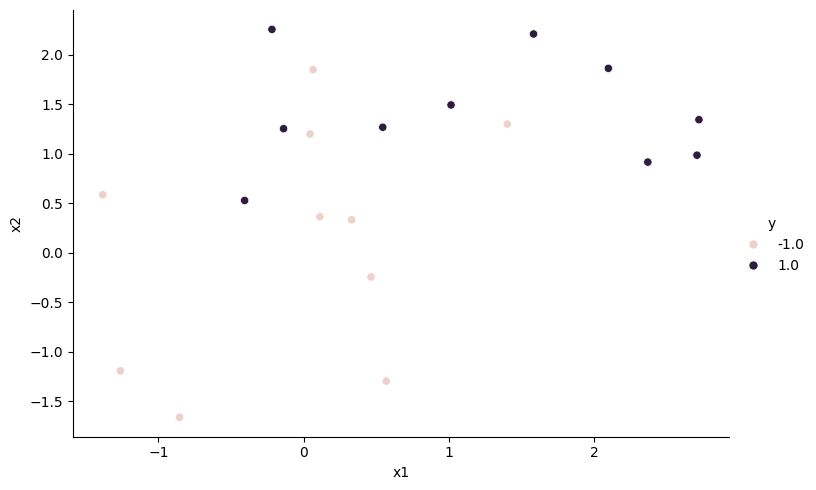

In [ ]:
sns.relplot(data=data, x='x1', y='x2', hue='y', aspect=1.5)
plt.show()

luego, aplicamos el clasificador,

In [ ]:
X = data.drop(columns = 'y')
y = data['y']

modelo = SVC(C = 10, kernel = 'linear', random_state=123)
modelo.fit(X, y)

SVC(C=10, kernel='linear', random_state=123)

Ahora podemos trazar el clasificador de vectores de soporte obtenido:

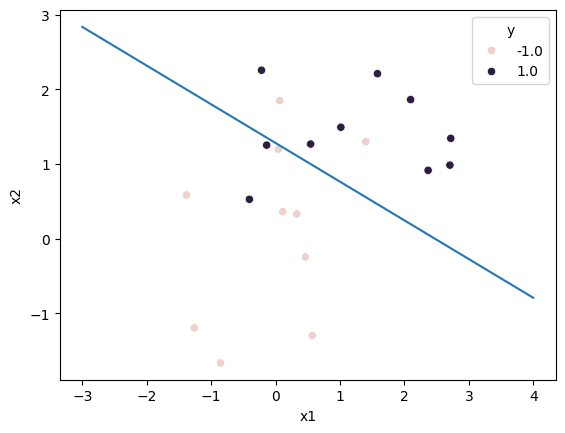

In [ ]:
import numpy as np
from seaborn import scatterplot
w = modelo.coef_[0]
b = modelo.intercept_[0]
x_visual = np.linspace(-3,4)
y_visual = -(w[0] / w[1]) * x_visual - b / w[1]

scatterplot(data = X, x='x1', y='x2', hue=y)
plt.plot(x_visual, y_visual)
plt.show()

Los vectores de soporte se representan como cruces y las observaciones restantes se trazan como círculos. Podemos determinar sus identidades de la siguiente manera:

In [ ]:
n= len(modelo.support_vectors_)
for i in range(n):
    print(data.index[(data['x1'] == modelo.support_vectors_[i][0]) | (data['x2'] == modelo.support_vectors_[i][1])].tolist())

[10]
[12]
[13]
[14]
[18]
[1]
[4]
[5]
[6]
[8]
[9]


Cambiemos el parámetro de costo a un valor más pequeño, es decir,

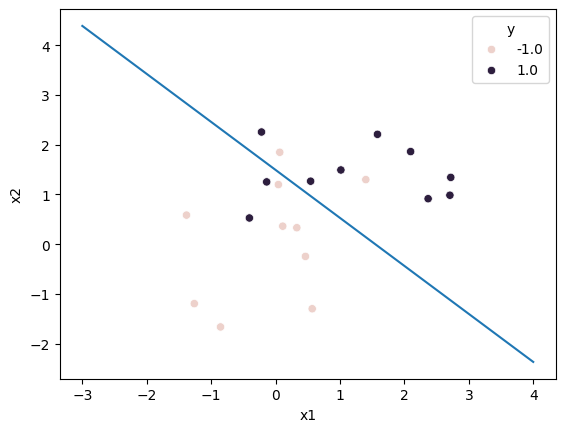

In [ ]:
modelo = SVC(C = 0.1, kernel = 'linear', random_state=123)
modelo.fit(X, y)

w = modelo.coef_[0]
b = modelo.intercept_[0]
x_visual = np.linspace(-3,4)
y_visual = -(w[0] / w[1]) * x_visual - b / w[1]

scatterplot(data = X, x='x1', y='x2', hue=y)
plt.plot(x_visual, y_visual)
plt.show()

In [ ]:
n= len(modelo.support_vectors_)
for i in range(n):
    print(data.index[(data['x1'] == modelo.support_vectors_[i][0]) | (data['x2'] == modelo.support_vectors_[i][1])].tolist())

[10]
[11]
[12]
[13]
[14]
[17]
[18]
[19]
[0]
[1]
[2]
[4]
[5]
[6]
[8]
[9]


Ahora que se utiliza un valor menor del parámetro de coste, obtenemos un mayor número de vectores de soporte, porque el margen es ahora más amplio

In [ ]:
param_grid = {'C': [0.001 , 0.01 , 0.1 , 1 ,5 ,10 ,100],'kernel': ['linear']}

grid = GridSearchCV(SVC(), param_grid, refit = True, verbose = 3)

grid.fit(X, y)

Fitting 5 folds for each of 7 candidates, totalling 35 fits
[CV 1/5] END ............C=0.001, kernel=linear;, score=0.750 total time=   0.0s
[CV 2/5] END ............C=0.001, kernel=linear;, score=0.500 total time=   0.0s
[CV 3/5] END ............C=0.001, kernel=linear;, score=0.750 total time=   0.0s
[CV 4/5] END ............C=0.001, kernel=linear;, score=1.000 total time=   0.0s
[CV 5/5] END ............C=0.001, kernel=linear;, score=0.750 total time=   0.0s
[CV 1/5] END .............C=0.01, kernel=linear;, score=0.750 total time=   0.0s
[CV 2/5] END .............C=0.01, kernel=linear;, score=0.500 total time=   0.0s
[CV 3/5] END .............C=0.01, kernel=linear;, score=0.750 total time=   0.0s
[CV 4/5] END .............C=0.01, kernel=linear;, score=1.000 total time=   0.0s
[CV 5/5] END .............C=0.01, kernel=linear;, score=0.750 total time=   0.0s
[CV 1/5] END ..............C=0.1, kernel=linear;, score=0.750 total time=   0.0s
[CV 2/5] END ..............C=0.1, kernel=linear;,

GridSearchCV(estimator=SVC(),
             param_grid={'C': [0.001, 0.01, 0.1, 1, 5, 10, 100],
                         'kernel': ['linear']},
             verbose=3)

In [ ]:
print(grid.best_params_)
print(grid.best_estimator_)

{'C': 0.001, 'kernel': 'linear'}
SVC(C=0.001, kernel='linear')


Con la función `predict()` puede ser usada para predecir etiquetas en un conjunto de datos de prueba. Comencemos generando el conjunto de entrenamiento,

In [ ]:
xtest = np.random.normal(0, 1, size=(20, 2))
y1 = np.ones((10,1))
y2= np.ones((10,1))
y2[:,0] = y2[:,0] -2
ytest = np.concatenate((y1, y2))
testdata = pd.DataFrame(xtest)
testdata["ytest"] = ytest
Nombres = ["x1","x2","ytest"]
testdata.columns = Nombres
testdata.loc[testdata['ytest'] == 1,['x1']]= testdata[['x1']] + 1
testdata.loc[testdata['ytest'] == 1,['x2']]= testdata[['x2']] + 1

Ahora, hacemos la predicción con el mejor modelo estimado,

In [ ]:
X_test = testdata.drop(columns = 'ytest')
y_test = testdata['ytest']

predictions = grid.predict(X_test)
print(classification_report(y_test, predictions))

              precision    recall  f1-score   support

        -1.0       0.80      0.80      0.80        10
         1.0       0.80      0.80      0.80        10

    accuracy                           0.80        20
   macro avg       0.80      0.80      0.80        20
weighted avg       0.80      0.80      0.80        20



y la matriz de confusión,

In [ ]:
confusion_matrix = pd.crosstab(
    y_test.ravel(),
    predictions,
    rownames=['Real'],
    colnames=['Predicción']
)
confusion_matrix

/tmp/ipykernel_1305/4114137186.py:2: FutureWarning: Series.ravel is deprecated. The underlying array is already 1D, so ravel is not necessary.  Use `to_numpy()` for conversion to a numpy array instead.
  y_test.ravel(),


Predicción,-1.0,1.0
Real,,
-1.0,8,2
1.0,2,8


 Coloquemos la función de costo en $0,01$,

In [ ]:
modelo = SVC(C = 0.01, kernel = 'linear', random_state=123)
modelo.fit(X, y)

predictions = modelo.predict(X_test)

confusion_matrix = pd.crosstab(
    y_test.ravel(),
    predictions,
    rownames=['Real'],
    colnames=['Predicción']
)
confusion_matrix

/tmp/ipykernel_1305/2628116920.py:7: FutureWarning: Series.ravel is deprecated. The underlying array is already 1D, so ravel is not necessary.  Use `to_numpy()` for conversion to a numpy array instead.
  y_test.ravel(),


Predicción,-1.0,1.0
Real,,
-1.0,8,2
1.0,2,8


Vemos que aumenta el error de clasificación en la clase -1.

## Support vector machine

Para ajustar una SVM utilizando un kernel no lineal, volvemos a utilizar la función `SVM()`, sin embargo, ahora utilizamos un valor diferente del parámetro kernel.

Para ajustar una SVM con un kernel polinomial utilizamos `kernel="poly"`, y para ajustar una SVM con un kernel radial utilizamos `kernel="rdf"`.

Primero generamos algunos datos con un límite de clase no lineal, como sigue:

In [ ]:
x2 = np.random.normal(0, 1, size=(200, 2))
y12 = np.ones((150,1))
y22= np.ones((50,1))
y22[:,0] = y22[:,0]+1
y2 = np.concatenate((y12, y22))
data2 = pd.DataFrame(x2)
data2[:100] = data2[:100] +2
data2[100:150] = data2[100:150] -2
data2["y"] = y2
Nombres = ["x1","x2","y"]
data2.columns = Nombres


Ploteamos los datos para asegurarnos que no tienen límites lineales,

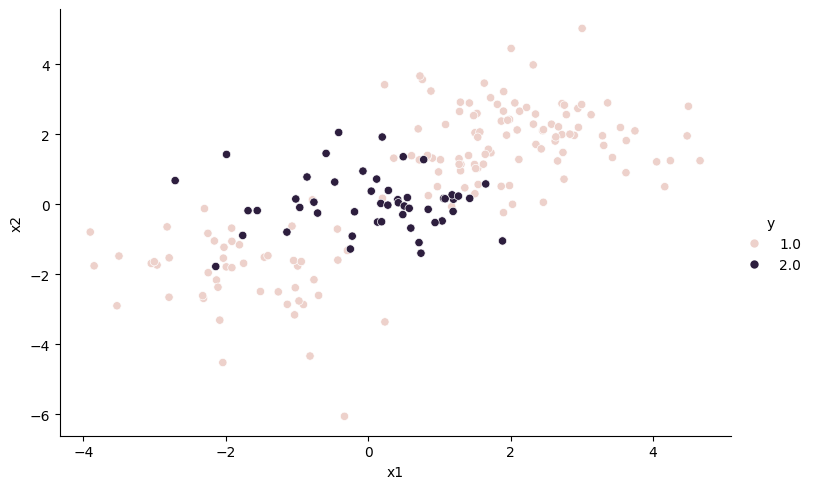

In [ ]:
sns.relplot(data=data2, x='x1', y='x2', hue='y', aspect=1.5)
plt.show()

Los datos se dividen aleatoriamente en grupos de entrenamiento y de prueba. A continuación, ajustamos los datos de entrenamiento utilizando la función `svm()` con un kernel radial y $\gamma = 1$:

In [ ]:
X2 = data2.drop(columns = 'y')
y2 = data2['y']

X_train, X_test, y_train, y_test = train_test_split(X2, y2, test_size=0.5, random_state=100)

modelo1 = SVC(C = 1, kernel = 'rbf', gamma= 1,  random_state=123)
modelo1.fit(X_train, y_train)

SVC(C=1, gamma=1, random_state=123)

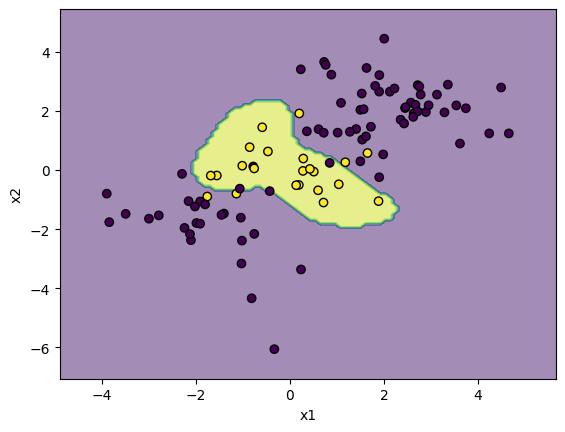

In [ ]:
from sklearn.inspection import DecisionBoundaryDisplay

disp = DecisionBoundaryDisplay.from_estimator(modelo1, X_train,
                                              response_method="predict",
                                              xlabel="x1", ylabel="x2",
                                              alpha=0.5)
disp.ax_.scatter(X_train["x1"], X_train["x2"], c=y_train, edgecolor="k")
plt.show()

El gráfico muestra que la SVM resultante tiene un límite decididamente no lineal.

Podemos ver en la figura que hay un buen número de errores de entrenamiento.

Si aumentamos el valor del coste, podemos reducir el número de errores de entrenamiento. Sin embargo, esto tiene el precio, se puede correr el riesgo de sobreajustar los datos.

In [ ]:
modelo2 = SVC(C = 100000, kernel = 'rbf', gamma= 1,  random_state=123)
modelo2.fit(X_train, y_train)

SVC(C=100000, gamma=1, random_state=123)

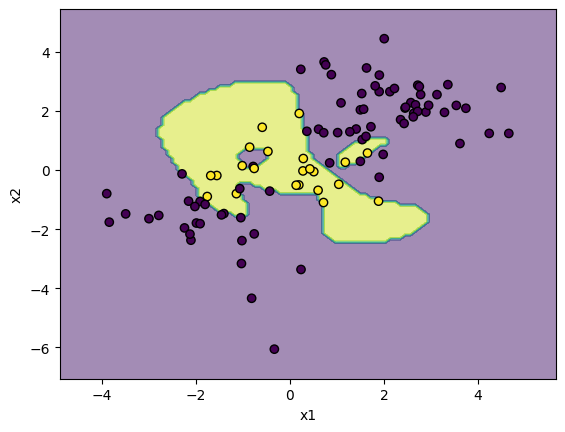

In [ ]:
disp = DecisionBoundaryDisplay.from_estimator(modelo2, X_train,
                                              response_method="predict",
                                              xlabel="x1", ylabel="x2",
                                              alpha=0.5)
disp.ax_.scatter(X_train["x1"], X_train["x2"], c=y_train, edgecolor="k")
plt.show()

Utilicemos la función `GridSearchCV` para realizar la mejor elección de γ y del costo para un modelo SVM con un kernel radial:

In [ ]:
param_grid = {'C': [0.1 , 1 , 10 , 100,1000], 'gamma': [0.5,1,2,3,4], 'kernel': ['rbf']}

grid = GridSearchCV(SVC(), param_grid, refit = True, verbose = 3)

grid.fit(X_train, y_train)

Fitting 5 folds for each of 25 candidates, totalling 125 fits
[CV 1/5] END ......C=0.1, gamma=0.5, kernel=rbf;, score=0.800 total time=   0.0s
[CV 2/5] END ......C=0.1, gamma=0.5, kernel=rbf;, score=0.800 total time=   0.0s
[CV 3/5] END ......C=0.1, gamma=0.5, kernel=rbf;, score=0.800 total time=   0.0s
[CV 4/5] END ......C=0.1, gamma=0.5, kernel=rbf;, score=0.750 total time=   0.0s
[CV 5/5] END ......C=0.1, gamma=0.5, kernel=rbf;, score=0.750 total time=   0.0s
[CV 1/5] END ........C=0.1, gamma=1, kernel=rbf;, score=0.800 total time=   0.0s
[CV 2/5] END ........C=0.1, gamma=1, kernel=rbf;, score=0.800 total time=   0.0s
[CV 3/5] END ........C=0.1, gamma=1, kernel=rbf;, score=0.800 total time=   0.0s
[CV 4/5] END ........C=0.1, gamma=1, kernel=rbf;, score=0.750 total time=   0.0s
[CV 5/5] END ........C=0.1, gamma=1, kernel=rbf;, score=0.750 total time=   0.0s
[CV 1/5] END ........C=0.1, gamma=2, kernel=rbf;, score=0.800 total time=   0.0s
[CV 2/5] END ........C=0.1, gamma=2, kernel=rbf

GridSearchCV(estimator=SVC(),
             param_grid={'C': [0.1, 1, 10, 100, 1000],
                         'gamma': [0.5, 1, 2, 3, 4], 'kernel': ['rbf']},
             verbose=3)

In [ ]:
print(grid.best_params_)
print(grid.best_estimator_)

{'C': 1, 'gamma': 3, 'kernel': 'rbf'}
SVC(C=1, gamma=3)


Podemos ver las predicciones del conjunto de prueba para este modelo.

In [ ]:
predictions = grid.predict(X_test)
print(classification_report(y_test, predictions))

              precision    recall  f1-score   support

         1.0       0.84      0.99      0.90        72
         2.0       0.93      0.50      0.65        28

    accuracy                           0.85       100
   macro avg       0.88      0.74      0.78       100
weighted avg       0.86      0.85      0.83       100



In [ ]:
confusion_matrix = pd.crosstab(
    y_test.ravel(),
    predictions,
    rownames=['Real'],
    colnames=['Predicción']
)
confusion_matrix

/tmp/ipykernel_1305/4114137186.py:2: FutureWarning: Series.ravel is deprecated. The underlying array is already 1D, so ravel is not necessary.  Use `to_numpy()` for conversion to a numpy array instead.
  y_test.ravel(),


Predicción,1.0,2.0
Real,,
1.0,71,1
2.0,14,14


## SVM para clases multiples

Si la respuesta es un factor que contiene más de dos niveles, la función SVC() realizará una clasificación multiclase utilizando el enfoque uno contra uno (La estrategia Uno contra Uno divide una clasificación multiclase en un problema de clasificación binaria por cada par de clases).

Exploramos aquí esa configuración generando una tercera clase de observaciones.

In [ ]:
x3 = np.random.normal(0, 1, size=(50, 2))
y23= np.ones((50,1))
y23[:,0] = y23[:,0]-1

data3 = pd.DataFrame(x3)
data3["y"] = y23
Nombres = ["x1","x2","y"]
data3.columns = Nombres

data3.loc[data3['y'] == 1,['x2']]= data3[['x2']] + 2

data_new = clients = pd.concat([data2, data3])

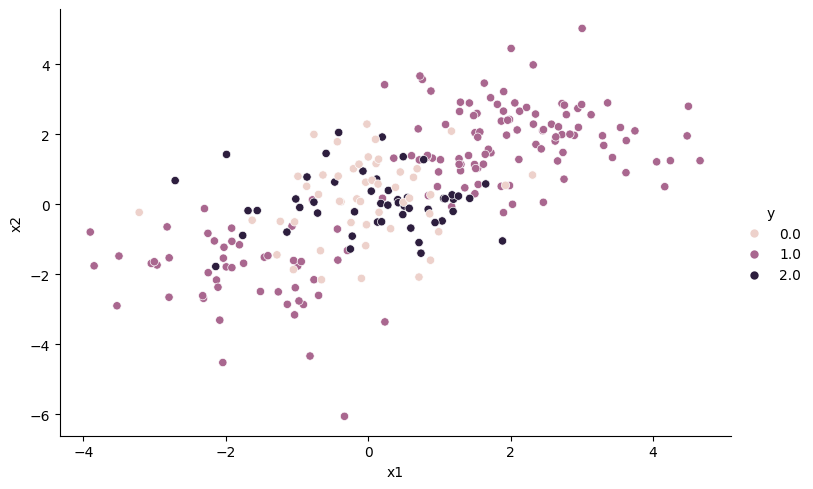

In [ ]:
sns.relplot(data=data_new, x='x1', y='x2', hue='y', aspect=1.5)
plt.show()

Ajustamos un SVM a los datos,

In [ ]:
X3 = data_new.drop(columns = 'y')
y3 = data_new['y']

modelo3 = SVC(C = 10, kernel = 'rbf', gamma= 1,  random_state=123)
modelo3.fit(X3, y3)

SVC(C=10, gamma=1, random_state=123)

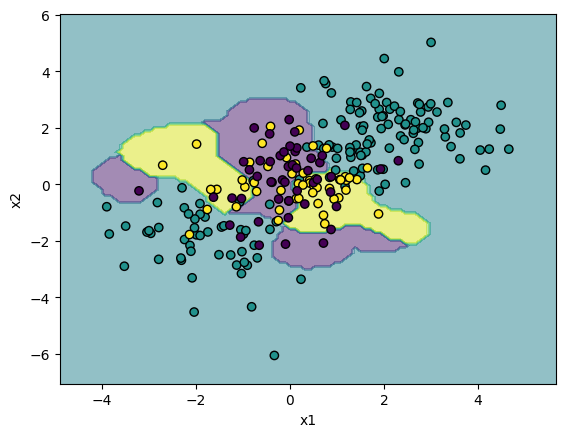

In [ ]:
disp = DecisionBoundaryDisplay.from_estimator(modelo3, X3,
                                              response_method="predict",
                                              xlabel="x1", ylabel="x2",
                                              alpha=0.5)
disp.ax_.scatter(X3["x1"], X3["x2"], c=y3, edgecolor="k")
plt.show()

## Aplicación a los datos de expresión génica

Examinamos ahora el conjunto de datos de Khan, que consiste en una serie de muestras de tejido correspondientes a cuatro tipos distintos de tumores pequeños de células azules redondas. Para cada muestra de tejido se dispone de mediciones de expresión génica. El conjunto de datos consta de datos de entrenamiento, xtrain e ytrain, y datos de prueba, xtest e ytest.

In [ ]:
khan_xtrain = pd.read_csv("Khan_xtrain.csv")
khan_xtest = pd.read_csv("Khan_xtest.csv")
khan_ytrain = pd.read_csv("Khan_ytrain.csv")
khan_ytest = pd.read_csv("Khan_ytest.csv")

FileNotFoundError: [Errno 2] No such file or directory: 'Khan_xtrain.csv'

VEmos las dimensiones de los set de datos,

In [ ]:
print(khan_xtrain.shape)

In [ ]:
print(khan_xtest.shape)

In [ ]:
print(khan_ytrain.shape)

In [ ]:
print(khan_ytest.shape)

In [ ]:
khan_xtrain = khan_xtrain.drop(['Unnamed: 0'], axis = 'columns', inplace=False)

In [ ]:
khan_xtrain.head()

In [ ]:
khan_xtest = khan_xtest.drop(['Unnamed: 0'], axis = 'columns', inplace=False)

In [ ]:
khan_ytrain = khan_ytrain.drop(['Unnamed: 0'], axis = 'columns', inplace=False)

In [ ]:
khan_ytest = khan_ytest.drop(['Unnamed: 0'], axis = 'columns', inplace=False)

In [ ]:
khan_ytrain.dtypes

In [ ]:
uniqueValues = khan_ytrain['x'].unique()
print(uniqueValues)

Utilizaremos un enfoque de vectores de soporte para predecir el subtipo de cáncer utilizando medidas de expresión génica. En este conjunto de datos, hay un gran número de características en relación con el número de observaciones. Esto sugiere que deberíamos utilizar un kernel lineal, porque la flexibilidad adicional que resultaría de utilizar un kernel polinomial o radial es innecesaria.

In [ ]:
modelo4 = SVC(C = 10, kernel = 'linear',  random_state=123)
modelo4.fit(khan_xtrain, khan_ytrain)

Lo que más nos interesa no es el rendimiento del clasificador de vectores de soporte en las observaciones de entrenamiento, sino su rendimiento en las observaciones de prueba.

In [ ]:
predictions = modelo4.predict(khan_xtest)
print(classification_report(khan_ytest, predictions))

In [ ]:
confusion_matrix = pd.crosstab(
    khan_ytest['x'].ravel(),
    predictions,
    rownames=['Real'],
    colnames=['Predicción']
)
confusion_matrix